# 自然语言处理

## 文本预处理

读取数据集

In [52]:
import collections
import re
from d2l import torch as d2l

d2l.DATA_HUB['time_machine'] = (d2l.DATA_URL + 'timemachine.txt',
                                '090b5e7e70c295757f55df93cb0a180b9691891a')

def read_time_machine():  #@save
    """将时间机器数据集加载到文本行的列表中"""
    with open(d2l.download('time_machine'), 'r') as f:
        lines = f.readlines()
    # 所有非英文的字符全部替换成空格-删除首位空格-字母全部小写
    return [re.sub('[^A-Za-z]+', ' ', line).strip().lower() for line in lines]

lines = read_time_machine()
print(f'# 文本总行数: {len(lines)}')
print(lines[0])
print(lines[10])

# 文本总行数: 3221
the time machine by h g wells
twinkled and his usually pale face was flushed and animated the


词元化

In [53]:
def tokenize(lines, token='word'):  #@save
    """将文本行拆分为单词或字符词元"""
    if token == 'word':
        # 按空格拆分字符串
        return [line.split() for line in lines]
    elif token == 'char':
        # 按字符拆分字符串
        return [list(line) for line in lines]
    else:
        print('错误：未知词元类型：' + token)

# tokens = tokenize(lines, 'char')
tokens = tokenize(lines)
for i in range(11):
    print(tokens[i])

['the', 'time', 'machine', 'by', 'h', 'g', 'wells']
[]
[]
[]
[]
['i']
[]
[]
['the', 'time', 'traveller', 'for', 'so', 'it', 'will', 'be', 'convenient', 'to', 'speak', 'of', 'him']
['was', 'expounding', 'a', 'recondite', 'matter', 'to', 'us', 'his', 'grey', 'eyes', 'shone', 'and']
['twinkled', 'and', 'his', 'usually', 'pale', 'face', 'was', 'flushed', 'and', 'animated', 'the']


词表：建立文字和数字之间的映射关系，让计算机能够用数字表示文本

In [54]:
def count_corpus(tokens):
    """统计词元的频率"""
    if len(tokens) == 0 or isinstance(tokens[0], list):
        tokens = [token for line in tokens for token in line]
    return collections.Counter(tokens)


class Vocab:
    def __init__(self, tokens=None, min_freq=0, reversed_token=None): # 需要提前保留的特殊词元
        if tokens is None:
            tokens = []
        if reversed_token is None:
            reversed_token = []
        # 按出现频率排序
        counter = count_corpus(tokens)
        self._token_freqs = sorted(counter.items(), key=lambda x: x[1], reverse=True)
        self._idx_to_token = ['<unk>'] + reversed_token
        self._token_to_idx = {token:idx for idx, token in enumerate(self._idx_to_token)}
        for token, freq in self._token_freqs:
            if freq < min_freq:
                break;
            if token not in self._idx_to_token:
                self._idx_to_token.append(token)
                self._token_to_idx[token] = len(self._idx_to_token) - 1

    def __len__(self):
        return len(self._idx_to_token)

    def __getitem__(self, tokens):
        if not isinstance(tokens, (list, tuple)):
            return self._token_to_idx.get(tokens, self.unk)
        return [self.__getitem__(token) for token in tokens]

    def to_tokens(self, indices):
        if not isinstance(indices, (list, tuple)):
            return self._idx_to_token[indices]
        return [self._idx_to_token[index] for index in indices]

    @property
    def unk(self):  # 未知词元的索引为0
        return 0
    @property
    def token_freqs(self):
        return self._token_freqs

    

In [55]:
vocab = Vocab(tokens)
print(list(vocab._token_to_idx.items())[:10])

[('<unk>', 0), ('the', 1), ('i', 2), ('and', 3), ('of', 4), ('a', 5), ('to', 6), ('was', 7), ('in', 8), ('that', 9)]


In [56]:
for i in [0, 10]:
    print('文本:', tokens[i])
    print('索引:', vocab[tokens[i]])

文本: ['the', 'time', 'machine', 'by', 'h', 'g', 'wells']
索引: [1, 19, 50, 40, 2183, 2184, 400]
文本: ['twinkled', 'and', 'his', 'usually', 'pale', 'face', 'was', 'flushed', 'and', 'animated', 'the']
索引: [2186, 3, 25, 1044, 362, 113, 7, 1421, 3, 1045, 1]


In [57]:
def load_corpus_time_machine(max_tokens=-1):
    lines = read_time_machine()
    tokens = tokenize(lines, token='char')
    vocab = Vocab(tokens)
    corpus = [vocab[token] for line in tokens for token in line]
    if max_tokens > 0:
        corpus = corpus[:max_tokens]
    return corpus, vocab

corpus, vocab = load_corpus_time_machine()
len(corpus), len(vocab)




(170580, 28)

## 语言模型和数据集

In [58]:
import random
import torch
from d2l import torch as d2l

tokens = d2l.tokenize(read_time_machine())
# 因为每个文本行不一定是一个句子或一个段落，因此我们把所有文本行拼接到一起
corpus_book = [token for line in tokens for token in line]
vocab = d2l.Vocab(corpus_book)
vocab.token_freqs[:10]

[('the', 2261),
 ('i', 1267),
 ('and', 1245),
 ('of', 1155),
 ('a', 816),
 ('to', 695),
 ('was', 552),
 ('in', 541),
 ('that', 443),
 ('my', 440)]

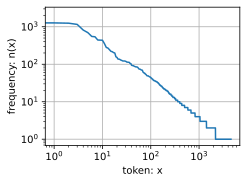

In [59]:
freqs = [freq for token, freq in vocab.token_freqs]
d2l.plot(freqs, xlabel='token: x', ylabel='frequency: n(x)',
         xscale='log', yscale='log')

N-gram（N 元语法模型）

In [60]:
# 二元组
bigram_tokens = [pair for pair in zip(corpus_book[:-1], corpus_book[1:])]
bigram_vocab = Vocab(bigram_tokens)
bigram_vocab.token_freqs[:10]
# 三元组
trigram_tokens = [triple for triple in zip(corpus_book[:-2], corpus_book[1:-1], corpus_book[2:])]
trigram_vocab = Vocab(trigram_tokens)
trigram_vocab.token_freqs[:10]

[(('the', 'time', 'traveller'), 59),
 (('the', 'time', 'machine'), 30),
 (('the', 'medical', 'man'), 24),
 (('it', 'seemed', 'to'), 16),
 (('it', 'was', 'a'), 15),
 (('here', 'and', 'there'), 15),
 (('seemed', 'to', 'me'), 14),
 (('i', 'did', 'not'), 14),
 (('i', 'saw', 'the'), 13),
 (('i', 'began', 'to'), 13)]

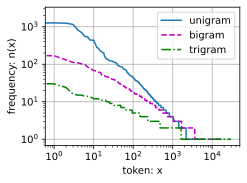

In [61]:
bigram_freqs = [freq for token, freq in bigram_vocab.token_freqs]
trigram_freqs = [freq for token, freq in trigram_vocab.token_freqs]
d2l.plot([freqs, bigram_freqs, trigram_freqs], xlabel='token: x',
         ylabel='frequency: n(x)', xscale='log', yscale='log',
         legend=['unigram', 'bigram', 'trigram'])

### 随机采样

In [62]:
def seq_data_iter_random(corpus, batch_size, num_steps):  #@save
    """使用随机抽样生成一个小批量子序列"""
    # 从随机偏移量开始对序列进行分区，随机范围包括num_steps-1
    corpus = corpus[random.randint(0, num_steps - 1):]
    # 减去1，是因为我们需要考虑标签
    num_subseqs = (len(corpus) - 1) // num_steps
    # 长度为num_steps的子序列的起始索引
    initial_indices = list(range(0, num_subseqs * num_steps, num_steps))
    # 在随机抽样的迭代过程中，
    # 来自两个相邻的、随机的、小批量中的子序列不一定在原始序列上相邻
    random.shuffle(initial_indices)

    def data(pos):
        # 返回从pos位置开始的长度为num_steps的序列
        return corpus[pos: pos + num_steps]

    num_batches = num_subseqs // batch_size
    for i in range(0, batch_size * num_batches, batch_size):
        # 在这里，initial_indices包含子序列的随机起始索引
        initial_indices_per_batch = initial_indices[i: i + batch_size]
        X = [data(j) for j in initial_indices_per_batch]
        Y = [data(j + 1) for j in initial_indices_per_batch]
        yield torch.tensor(X), torch.tensor(Y)

In [63]:
my_seq = list(range(35))
for X, Y in seq_data_iter_random(my_seq, batch_size=2, num_steps=5):
    print('X: ', X, '\nY:', Y)

X:  tensor([[19, 20, 21, 22, 23],
        [24, 25, 26, 27, 28]]) 
Y: tensor([[20, 21, 22, 23, 24],
        [25, 26, 27, 28, 29]])
X:  tensor([[ 9, 10, 11, 12, 13],
        [ 4,  5,  6,  7,  8]]) 
Y: tensor([[10, 11, 12, 13, 14],
        [ 5,  6,  7,  8,  9]])
X:  tensor([[29, 30, 31, 32, 33],
        [14, 15, 16, 17, 18]]) 
Y: tensor([[30, 31, 32, 33, 34],
        [15, 16, 17, 18, 19]])


### 顺序分区

In [64]:
def seq_data_iter_sequential(corpus, batch_size, num_steps):
    # 使用顺序分区生成一小批量的子序列
    # 从随机偏移量开始划分序列
    offset = random.randint(0, num_steps)
    # - offset：因为前面 2 个词元被跳过了。-1 是因为还要留出下一个字符作为训练标签。 保证最终使用的词元数量是batc_size的整数倍。
    num_tokens = ((len(corpus) - offset - 1) // batch_size) * batch_size
    Xs = torch.tensor(corpus[offset: offset + num_tokens])
    Ys = torch.tensor(corpus[offset + 1: offset + 1 + num_tokens])
    # 按 batch_size 的大小拆分成多个批次
    Xs, Ys = Xs.reshape(batch_size, -1), Ys.reshape(batch_size, -1)
    # 按步长 step 拆分成多个子序列
    num_batches = Xs.shape[1] // num_steps
    for i in range(0, num_steps*num_batches, num_steps):
        X = Xs[:, i:i+num_steps]
        y = Ys[:, i:i+num_steps]
        yield X, y

In [65]:
for X, y in seq_data_iter_sequential(my_seq, batch_size=2, num_steps=5):
    print('X: ', X, '\nY:', y)

X:  tensor([[ 5,  6,  7,  8,  9],
        [19, 20, 21, 22, 23]]) 
Y: tensor([[ 6,  7,  8,  9, 10],
        [20, 21, 22, 23, 24]])
X:  tensor([[10, 11, 12, 13, 14],
        [24, 25, 26, 27, 28]]) 
Y: tensor([[11, 12, 13, 14, 15],
        [25, 26, 27, 28, 29]])


In [66]:
class SeqDataLoader:  #@save
    """加载序列数据的迭代器"""
    def __init__(self, batch_size, num_steps, use_random_iter, max_tokens):
        if use_random_iter:
            self.data_iter_fn = seq_data_iter_random
        else:
            self.data_iter_fn = seq_data_iter_sequential
        self.corpus, self.vocab = load_corpus_time_machine(max_tokens)
        self.batch_size, self.num_steps = batch_size, num_steps

    def __iter__(self):
        return self.data_iter_fn(self.corpus, self.batch_size, self.num_steps)

In [67]:
def load_data_time_machine(batch_size, num_steps,  #@save
                           use_random_iter=False, max_tokens=10000):
    """返回时光机器数据集的迭代器和词表"""
    data_iter = SeqDataLoader(
        batch_size, num_steps, use_random_iter, max_tokens)
    return data_iter, data_iter.vocab

## 编码器/解码器

In [68]:
from torch import nn

#@save
class Encoder(nn.Module):
    """编码器-解码器架构的基本编码器接口"""
    def __init__(self, **kwargs):
        super(Encoder, self).__init__(**kwargs)

    def forward(self, X, *args):
        raise NotImplementedError # 还没实现对应方法，调用会抛出异常

In [69]:
from torch import nn

#@save
class Encoder(nn.Module):
    """编码器-解码器架构的基本编码器接口"""
    def __init__(self, **kwargs):
        super(Encoder, self).__init__(**kwargs)

    def forward(self, X, *args):
        raise NotImplementedError #还没实现对应方法，调用会抛出异常

合并编码器和解码器

enc_X：原始输入，传给编码器。



enc_outputs：编码器提取出的上下文特征。



dec_state：根据编码器输出，初始化解码器的状态。



dec_X：解码器自己的输入。



return self.decoder(dec_X, dec_state)：结合两部分信息，返回解码器的输出

In [70]:
#@save
class EncoderDecoder(nn.Module):
    """编码器-解码器架构的基类"""
    def __init__(self, encoder, decoder, **kwargs):
        super(EncoderDecoder, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, enc_X, dec_X, *args):
        enc_outputs = self.encoder(enc_X, *args)
        dec_state = self.decoder.init_state(enc_outputs, *args)
        return self.decoder(dec_X, dec_state)

## Seq2seq
编码器解码器架构

### 编码器

In [71]:
class Seq2seqEncoder(d2l.Encoder):
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers, dropout=0, **kwargs):
        super().__init__(**kwargs)
        # 词嵌入表，shape(vocab_size, embed_size)
        self.embedding = nn.Embedding(vocab_size, embed_size)
        # GRU层
        self.rnn = nn.GRU(embed_size, num_hiddens, num_layers, dropout=dropout)

    def forward(self, X, *args):
        X = self.embedding(X)
        X.shape
        # 交换维度（维度一是时间步，一个单词一个时间步， 维度二是句子个数）
        # GRU 在每个时间步处理的是 Batch 中所有句子在相同位置的 Embedding 向量，而不是原始单词。
        X = X.permute(1, 0, 2)
        # state 是所有 GRU 层在最后一个时间步的隐藏状态。output 是最后一层 GRU 在每个时间步的输出
        output, state = self.rnn(X)
        return output, state

In [72]:
# 举个例子
encoder = Seq2seqEncoder(vocab_size=10, embed_size=8, num_hiddens=16, num_layers=2)
encoder.eval()
X = torch.zeros((4, 7), dtype=torch.long)
output, state = encoder(X)
output.shape

torch.Size([7, 4, 16])

In [73]:
state.shape

torch.Size([2, 4, 16])

### 解码器

In [74]:
class Seq2seqDecoder(d2l.Decoder):
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers, dropout=0, **kwargs):
        super().__init__(**kwargs)
        self.embedding = nn.Embedding(vocab_size, embed_size)
        # embedding和上下文向量（Context）拼接作为输入
        self.rnn = nn.GRU(embed_size + num_hiddens, num_hiddens, num_layers, dropout=dropout) 
        self.dense = nn.Linear(num_hiddens, vocab_size) # 输出预测的下一次词的得分，输入维度是GRU输出维度，输出维度是词表大小

    def init_state(self, enc_outputs, *args):
        return enc_outputs[1]

    def forward(self, X, state):
        X = self.embedding(X).permute(1, 0, 2)
        context = state[-1].repeat(X.shape[0], 1, 1)
        X_and_context = torch.cat((X, context), dim=2)
        output, state = self.rnn(X_and_context, state)
        output = self.dense(output).permute(1, 0, 2)
        return output, state

In [75]:
decoder = Seq2seqDecoder(vocab_size=10, embed_size=8, num_hiddens=16,
                         num_layers=2)
decoder.eval()
state = decoder.init_state(encoder(X))
output, state = decoder(X, state)
output.shape, state.shape

(torch.Size([4, 7, 10]), torch.Size([2, 4, 16]))

### 损失函数

一个 Batch 里面有多条句子，但是每条句子的长度可能不一样。

例如：
- 句子 1：我 喜欢 苹果（3 个 Token）
- 句子 2：他 喜欢（2 个 Token）
  
为了组成一个形状规则的张量，通常会用 `<pad>` 补齐：

- 句子1：[我, 喜欢, 苹果]
- 句子2：[他, 喜欢, `<pad>`]

但`<pad>` 不是真正需要学习的语言内容。

所以我们需要一个 Mask（掩码），标记哪些位置有效，哪些位置应该忽略。

In [76]:
def sequence_mask(X, valid_len, value=0):
    maxlen = X.size(1)
    mask = torch.arange((maxlen), dtype=torch.float32,
                       device=X.device)[None, :] < valid_len[:, None]
    X[~mask] = value
    return X

X = torch.tensor([[1, 2, 3], [4, 5, 6]])   
sequence_mask(X, torch.tensor([1, 2])) 

tensor([[1, 0, 0],
        [4, 5, 0]])

In [77]:
X = torch.ones(2, 3, 4)
sequence_mask(X, torch.tensor([1, 2]), value=-1)

tensor([[[ 1.,  1.,  1.,  1.],
         [-1., -1., -1., -1.],
         [-1., -1., -1., -1.]],

        [[ 1.,  1.,  1.,  1.],
         [ 1.,  1.,  1.,  1.],
         [-1., -1., -1., -1.]]])

假设我们正在训练机器翻译模型。

Decoder 预测一句英文：

`I like apples`

但是为了把不同长度的句子放进同一个 Batch，我们可能需要补充 `<pad>`。

例如：
- 句子1：[I, like, `<eos>`, `<pad>`]
- 句子2：[I, like, apples, `<eos>`] 
其中 `<eos>` 表示句子结束，`<pad>` 是为了对齐长度而添加的填充符。


然而计算损失时，我们希望模型学习预测真正的 Token，而不是让填充的 `<pad>` 也参与损失计算。

因此需要：
- CrossEntropyLoss：计算每个 Token 位置的预测损失。
- Mask：把无效的填充位置对应的损失清零。


In [78]:
# 损失函数
class MaskedSoftmaxCELoss(nn.CrossEntropyLoss):
    """带遮蔽的softmax交叉熵损失函数"""
    # pred的形状：(batch_size,num_steps,vocab_size)
    # 每个批次batch_size个句子，每个句子num_steps个词，每个词vocab_size个词概率
    # label的形状：(batch_size,num_steps)
    # 每个位置真正的token_id
    # valid_len的形状：(batch_size,)
    # 每条句子的有效 Token 数量
    def forward(self, pred, label, valid_len):
        weights = torch.ones_like(label)
        weights = sequence_mask(weights, valid_len)
        self.reduction='none'
        unweighted_loss = super(MaskedSoftmaxCELoss, self).forward(
            pred.permute(0, 2, 1), label) # PyTorch 的 CrossEntropyLoss 要求类别维度（这里是词表维度）放在第 1 维。
        weighted_loss = (unweighted_loss * weights).mean(dim=1)
        return weighted_loss

In [79]:

loss = MaskedSoftmaxCELoss()

result = loss(
    torch.ones(3, 4, 10),
    torch.ones((3, 4), dtype=torch.long),
    torch.tensor([4, 2, 0])
)

print("损失函数返回值：", result)
print("返回值类型：", type(result))


损失函数返回值： tensor([2.3026, 1.1513, 0.0000])
返回值类型： <class 'torch.Tensor'>


In [80]:
loss = MaskedSoftmaxCELoss()
loss(torch.ones(3, 4, 10), torch.ones((3, 4), dtype=torch.long),
     torch.tensor([4, 2, 0]))

tensor([2.3026, 1.1513, 0.0000])

### 训练

假设训练任务是中译英：
- 输入 X：我 喜欢 苹果
- 真实答案 Y：I like apples
  
一次训练的流程是：
① 从 data_iter 取出一个 Batch

- 中文 X、英文 Y、各自的有效长度

② Encoder + Decoder

- 根据输入句子，预测英文 Token 的得分

③ Loss

- 比较预测结果和真实英文，计算误差

④ backward()

 - 计算每个可训练参数的梯度

⑤ optimizer.step()

 - 更新参数，争取降低后续预测误差

处理下一个 Batch，不断重复


###  Decoder 输入与真实标签的对应关系（理解了就读懂了）

#### 第一条句子：I like apples

| | 位置 1 | 位置 2 | 位置 3 | 位置 4 |
|---|---|---|---|---|
| **Decoder 输入** | `<bos>` | I | like | apples |
| **真实标签 Y** | I | like | apples | `<eos>` |

####  第二条句子：I like

| | 位置 1 | 位置 2 | 位置 3 | 位置 4 |
|---|---|---|---|---|
| **Decoder 输入** | `<bos>` | I | like | `<eos>` |
| **真实标签 Y** | I | like | `<eos>` | `<pad>` |

#### 说明

- **`<bos>`**：序列开始符，用于启动 Decoder。
- **`<eos>`**：序列结束符，需要模型学习预测，因此参与损失计算。
- **`<pad>`**：填充符，仅用于对齐序列长度，不参与损失计算。
- **`Y_valid_len = [4, 3]`**：两条句子的有效 Token 数量，包含 `<eos>`，但不包含 `<pad>`。

**核心关系：**

`dec_input = torch.cat([bos, Y[:, :-1]], dim=1)`

即：在真实目标序列 `Y` 前添加 `<bos>`，同时移除最后一个 Token，构成 Decoder 的输入。这就是自生成模型，根据当前位置预测下一个位置


In [81]:

def train_seq2seq(net, data_iter, lr, num_epochs, tgt_vocab, device):
    """训练序列到序列的模型"""
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

    def xavier_init_weights(m):
        if type(m) == nn.Linear:
            nn.init.xavier_uniform_(m.weight)
        if type(m) == nn.GRU:
            for param in m._flat_weights_names:
                if "weight" in param:
                    w = m._parameters[param]
                    if w is not None:
                        nn.init.xavier_uniform_(w)

    net.apply(xavier_init_weights)
    net.to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    loss = MaskedSoftmaxCELoss()
    net.train()
    animator = d2l.Animator(xlabel='epoch', ylabel='loss', xlim=[10, num_epochs])
    for epoch in range(num_epochs):
        timer = d2l.Timer()
        metric = d2l.Accumulator(2)
        for batch in data_iter:
            optimizer.zero_grad()
            X, X_valid_len, Y, Y_valid_len = [x.to(device) for x in batch]
            bos = torch.tensor([tgt_vocab['<bos>']]*Y.shape[0], device=device).reshape(-1,1) # 获取开始字符 <bos> 的词表编号，后续要拼接作为解码器的输入
            dec_input = torch.cat([bos, Y[:, :-1]], 1) # 拼接开始字符 <bos> 和目标序列的[:-1]部分作为解码器的输入
            Y_hat, _ = net(X, dec_input, X_valid_len) # forward
            l = loss(Y_hat, Y, Y_valid_len)
            l.sum().backward()
            # 梯度裁剪,因为 GRU 需要
            d2l.grad_clipping(net, 1)
            num_tokens = Y_valid_len.sum()
            optimizer.step()
            with torch.no_grad():
                metric.add(l.sum(), num_tokens)
        if (epoch + 1) % 10 == 0:
            animator.add(epoch + 1, (metric[0] / metric[1],))
    print(f'loss {metric[0] / metric[1]:.3f}, {metric[1] / timer.stop():.1f} '
        f'tokens/sec on {str(device)}')


loss 0.019, 15719.3 tokens/sec on mps


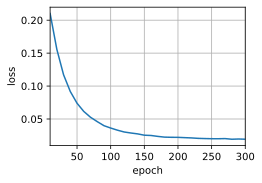

In [82]:
embed_size, num_hiddens, num_layers, dropout = 32, 32, 2, 0.1
batch_size, num_steps = 64, 10
lr, num_epochs, device = 0.005, 300, torch.device("mps" if torch.backends.mps.is_available() else "cpu")

train_iter, src_vocab, tgt_vocab = d2l.load_data_nmt(batch_size, num_steps)
encoder = Seq2seqEncoder(len(src_vocab), embed_size, num_hiddens, num_layers,
                        dropout)
decoder = Seq2seqDecoder(len(tgt_vocab), embed_size, num_hiddens, num_layers,
                        dropout)
net = EncoderDecoder(encoder, decoder)
train_seq2seq(net, train_iter, lr, num_epochs, tgt_vocab, device)

### 预测

训练时，我们已经知道正确答案，因此可以采用 Teacher Forcing：

| 时间步 | Decoder 输入 | 真实标签 |
|---|---|---|
| 1 | `<bos>` | I |
| 2 | I | love |
| 3 | love | you |
| 4 | you | `<eos>` |

但现在是预测阶段，**我们根本不知道正确的英文翻译是什么。**

所以 Decoder 必须：

1. 先输入 `<bos>`，预测第一个 Token。
2. 把第一个预测结果作为第二步的输入。
3. 不断重复，逐个生成 Token。
4. 一旦预测出 `<eos>`，立即结束。

**预测过程示例（假设模型翻译正确）**

| 当前输入 | Decoder | 预测结果 |
|:---:|:---:|:---:|
| `<bos>` | → GRU → | i |
| i | → GRU → | love |
| love | → GRU → | you |
| you | → GRU → | `<eos>` |


> 每次预测不仅传入上一步的 Token，还会传入上一步更新后的隐藏状态。

这种每次选择最高得分 Token 的方法叫 **Greedy Decoding（贪心解码）**。

| 参数 | 含义 |
|---|---|
| `net` | 已经训练好的 Seq2Seq 模型 |
| `src_sentence` | 准备翻译的源语言句子 |
| `src_vocab` | 源语言词表 |
| `tgt_vocab` | 目标语言词表 |
| `num_steps` | 最大预测步数，同时用于源序列截断与填充 |
| `device` | 模型使用的计算设备 |
| `save_attention_weights` | 是否保存注意力权重，默认 `False` |

In [83]:
def predict_seq2seq(net, src_sentence, src_vocab, tgt_vocab, num_steps,
                    device, save_attention_weights=False):
    """序列到序列模型的预测"""
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
    net.to(device)

    # 在预测时将net设置为评估模式
    net.eval()
    src_tokens = src_vocab[src_sentence.lower().split(' ')] + [
        src_vocab['<eos>']]
    enc_valid_len = torch.tensor([len(src_tokens)], device=device)
    src_tokens = d2l.truncate_pad(src_tokens, num_steps, src_vocab['<pad>'])
    # 添加批量轴
    enc_X = torch.unsqueeze(
        torch.tensor(src_tokens, dtype=torch.long, device=device), dim=0)
    enc_outputs = net.encoder(enc_X, enc_valid_len)
    dec_state = net.decoder.init_state(enc_outputs, enc_valid_len)
    # 添加批量轴
    dec_X = torch.unsqueeze(torch.tensor(
        [tgt_vocab['<bos>']], dtype=torch.long, device=device), dim=0)
    output_seq = [] # 保存预测的 token_id
    attention_weight_seq = []
    for _ in range(num_steps):
        Y, dec_state = net.decoder(dec_X, dec_state)
        # 我们使用具有预测最高可能性的词元，作为解码器在下一时间步的输入
        dec_X = Y.argmax(dim=2)
        # 把预测输出（tensor)转换为整数索引，看是否对应<eos> 
        pred = dec_X.squeeze(dim=0).type(torch.int32).item()
        # 保存注意力权重（稍后讨论）
        if save_attention_weights:
            attention_weight_seq.append(net.decoder.attention_weights)
        # 一旦序列结束词元被预测，输出序列的生成就完成了
        if pred == tgt_vocab['<eos>']:
            break
        output_seq.append(pred)
    return ' '.join(tgt_vocab.to_tokens(output_seq)), attention_weight_seq


### BLEU

评价翻译的好不好

In [84]:
import math
def bleu(pred_seq, label_seq, k):  #@save
    """计算BLEU"""
    pred_tokens, label_tokens = pred_seq.split(' '), label_seq.split(' ')
    len_pred, len_label = len(pred_tokens), len(label_tokens)
    score = math.exp(min(0, 1 - len_label / len_pred))
    for n in range(1, k + 1):
        num_matches, label_subs = 0, collections.defaultdict(int)
        for i in range(len_label - n + 1):
            label_subs[' '.join(label_tokens[i: i + n])] += 1
        for i in range(len_pred - n + 1):
            if label_subs[' '.join(pred_tokens[i: i + n])] > 0:
                num_matches += 1
                label_subs[' '.join(pred_tokens[i: i + n])] -= 1
        score *= math.pow(num_matches / (len_pred - n + 1), math.pow(0.5, n))
    return score

In [85]:
engs = ['go .', "i lost .", 'he\'s calm .', 'i\'m home .']
fras = ['va !', 'j\'ai perdu .', 'il est calme .', 'je suis chez moi .']
for eng, fra in zip(engs, fras):
    translation, attention_weight_seq = predict_seq2seq(
        net, eng, src_vocab, tgt_vocab, num_steps, device)
    print(f'{eng} => {translation}, bleu {bleu(translation, fra, k=2):.3f}')

go . => va <unk> !, bleu 0.000
i lost . => j'ai perdu ., bleu 1.000
he's calm . => il est mouillé foutre partie ., bleu 0.473
i'm home . => je suis faible ., bleu 0.512


# 核心思想：Seq2Seq 在建模条件概率

## 1. 要学的是什么概率

机器翻译的目标是：已知源语言句子 $X$（如英语 `I love you`），生成目标语言句子 $Y$（如法语 `Je t'aime`）。

模型要学的是**条件概率**，不是 $P(Y)$：

$$P(Y \mid X)$$

由于 Decoder 是逐个 Token 生成的，可以按链式法则拆成每一步的条件概率相乘：

$$P(Y \mid X) = \prod_{t=1}^{T} P(y_t \mid y_1, \ldots, y_{t-1}, X)$$

- $X$：完整的源语言句子
- $y_t$：当前要预测的目标 Token
- $y_{<t} = y_1, \ldots, y_{t-1}$：之前已经生成的目标 Token

**每一步预测都依赖两个条件：源语言整句 $X$ ＋ 已生成的目标 Token $y_{<t}$。**

> 注意：Encoder-Decoder 是一种**网络架构**，条件概率是我们用它来**建模的对象**。

## 2. 神经网络不是按传统公式算条件概率

传统概率论中：

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}$$

这需要统计联合概率和边缘概率。但语言的组合几乎无穷，不可能统计出所有句子和译文的联合概率。

神经网络的做法是：**用参数 $\theta$ 构造一个函数，直接输出条件概率分布**：

$$h_t = f_\theta(X, y_{<t}) \qquad \text{（隐藏层：提取条件信息）}$$

$$z_t = W h_t + b \qquad \text{（Dense：得到词表上每个 Token 的分数）}$$

$$P_\theta(y_t = i \mid X, y_{<t}) = \mathrm{Softmax}(z_t)_i = \frac{e^{z_{t,i}}}{\sum_{j=1}^{V} e^{z_{t,j}}} \qquad \text{（Softmax：转成概率）}$$

- **隐藏状态 $h_t$ 本身不是概率**，只是包含条件信息的特征表示；概率是最后经过 Softmax 才得到的。
- 网络输出的是**模型估计的概率**，不一定等于现实中真实的条件概率。

## 3. 代码中哪里体现了条件概率

| 数学概念 | 对应代码 | 作用 |
|---|---|---|
| 源语言条件 $X$ | `enc_outputs = self.encoder(enc_X)` | Encoder 把源句编码成隐藏状态 |
| 把 $X$ 传给 Decoder | `dec_state = self.decoder.init_state(enc_outputs)` | 用 Encoder 最终隐藏状态初始化 Decoder |
| $X$ 参与每一步 | `context = state[-1].repeat(...)` + `torch.cat((X, context), dim=2)` | 每个时间步都拼接源句信息 |
| 目标历史 $y_{<t}$ | `dec_input = torch.cat([bos, Y[:, :-1]], 1)` + GRU 隐藏状态递推 | 当前输入 + 之前的记忆 |
| 综合所有条件得到 $h_t$ | `output, state = self.rnn(X_and_context, state)` | $h_t = f_\theta(X, y_{<t})$ |
| 分数 $z_t$ | `self.dense(output)` | 输出维度 = 词表大小 `vocab_size` |
| 概率 + 损失 | `MaskedSoftmaxCELoss`（继承 `nn.CrossEntropyLoss`） | 内部自带 LogSoftmax |

**为什么代码里看不到 Softmax？**
- **训练时**：`CrossEntropyLoss` 内部已经做了 LogSoftmax，所以 Decoder 只输出分数（logits）。
- **预测时**：`dec_X = Y.argmax(dim=2)` 直接取分数最大的 Token。Softmax 不改变大小顺序，分数最大的 Token 概率也最大，所以不用显式算概率。

**条件概率的直观体现**：即使 Decoder 当前输入都是 `<bos>`，只要 Encoder 输入的源句不同，输出的概率分布就不同。比如源句 `I love you` 时第一个词 `je` 的概率高，源句 `You love me` 时第一个词 `tu` 的概率高（示例，非真实输出）。

## 4. 网络怎么学到正确的条件概率

靠交叉熵损失。对每个真实目标 Token，最小化：

$$L_t = -\log P_\theta(y_t^{\text{真实}} \mid X, y_{<t})$$

反向传播调整参数 $\theta$，让**真实 Token 的预测概率越来越高**。这在概率上就是**最大似然估计**。

`MaskedSoftmaxCELoss` 在此基础上用 `sequence_mask` 把 `<pad>` 位置的损失清零，只对真实 Token（包括 `<eos>`）计算。

## 5. 总结

| 层次 | 作用 |
|---|---|
| 隐藏层（Encoder + GRU） | 学习和表示条件信息 $X$、$y_{<t}$ |
| Dense + Softmax | 根据条件信息生成下一个 Token 的概率分布 |
| 交叉熵 + 反向传播 | 让这个分布逐渐接近训练数据中的规律 |

**一句话：Seq2Seq 用隐藏状态表示源语言和已生成的目标历史，再通过 Dense 和 Softmax 输出下一个 Token 的条件概率；整句翻译的概率就是每一步条件概率的乘积。**

后面的 Attention、Transformer、GPT 也都是在建模「下一个 Token 的条件概率」，变的是模型**如何获取和利用条件信息**。